In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# ========== 数据路径(改成你自己的) ==========
DATA_PATH = r"D:\桌面\练习数据\真实数据集\online_retail.csv"

# ========== 原始数据:只做一次性格式转换,永不筛选 ==========
raw = pd.read_csv(DATA_PATH)
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["Sales"] = raw["Quantity"] * raw["UnitPrice"]

# ========== 工作副本:每次分析都从这里开始 ==========
df = raw.copy()

print(df.shape)
print(df.isna().sum())

(541909, 9)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Sales               0
dtype: int64


In [2]:
df.info()
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
 8   Sales        541909 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 37.2+ MB
            Quantity                    InvoiceDate      UnitPrice  \
count  541909.000000                         541909  541909.000000   
mean        9.552250  2011-07-04 13:34:57.156386048       4.611114   
min    -80995.000000            2010-12-01 08:26

In [3]:
#多少行、多少列、每列什么类型
print(df.shape)
print(df.dtypes)

(541909, 9)
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
Sales                 float64
dtype: object


In [4]:
# 缺失值分布：哪列缺得多？缺多少？
print(df.isna().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Sales               0
dtype: int64


In [5]:
# 日期范围、客户数、商品数、国家数
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("日期范围为：",df["InvoiceDate"].min(),"~",df["InvoiceDate"].max())
print("客户数为：",df["CustomerID"].nunique())
print("商品数为：",df["StockCode"].nunique())
print("国家数为：",df["Country"].nunique())

日期范围为： 2010-12-01 08:26:00 ~ 2011-12-09 12:50:00
客户数为： 4372


商品数为： 4070
国家数为： 38


4. **定义口径**：你的"有效销售"指什么？（提示：排除 C 开头发票、排除 Quantity<=0）
排除C开头的发票，排除Quantity<=0,排除UnitPrice<=0,排除找不到CustomersID
## 口径定义

### 基础清洗（所有分析都适用）
- 排除 InvoiceNo 以 "C" 开头的取消单（9,288 行）
- 排除 Quantity <= 0（退货/异常，10,624 行）
- 排除 UnitPrice <= 0（2,517 行）

### 客户维度分析时，额外排除
- 排除 CustomerID 缺失的行（135,080 行，占 25%，但贡献 16.4% 销售额）

### 两种口径的销售额
- 全量口径（含无ID订单）：10,666,684
- 客户口径（仅有ID订单）：8,911,407

In [6]:
# 总销售额（注意口径！）
# 每次分析都从 raw 派生一份,保证可重复执行
df = raw.copy()

# 排除取消单：InvoiceNo 以 C 开头
df = df[~df["InvoiceNo"].str.startswith("C")]
# 排除 Quantity <= 0
df = df[df["Quantity"] > 0]
# 排除 UnitPrice <= 0
df = df[df["UnitPrice"] > 0]

print(f"基础清洗后行数：{len(df):,}")
total_sales = df["Sales"].sum()
print(f"总销售额：{total_sales:,.0f}")

基础清洗后行数：530,104
总销售额：10,666,685


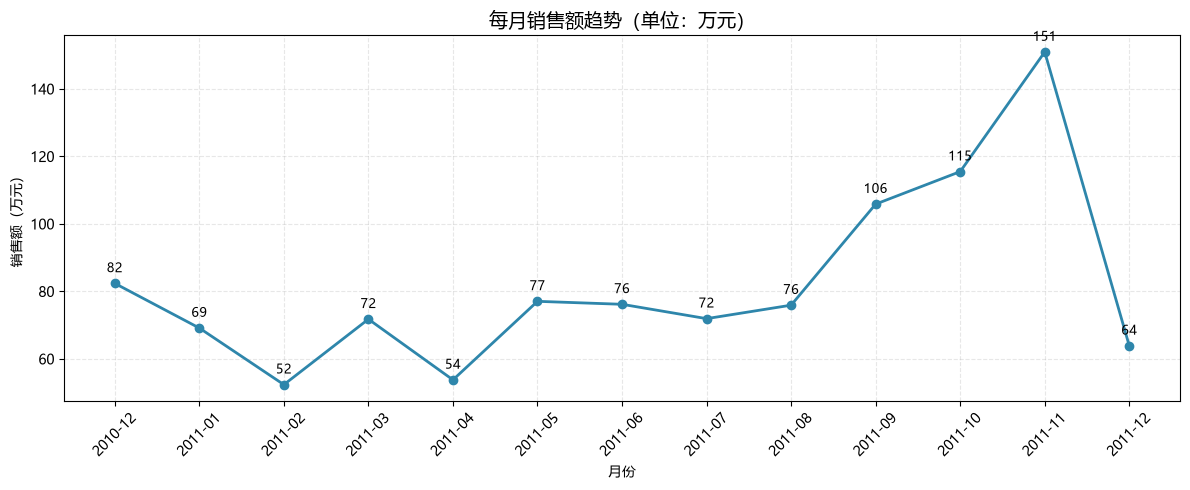

   YearMonth       Sales  Sales_Wan
0    2010-12   823746.14      82.37
1    2011-01   691364.56      69.14
2    2011-02   523631.89      52.36
3    2011-03   717639.36      71.76
4    2011-04   537808.62      53.78
5    2011-05   770536.02      77.05
6    2011-06   761739.90      76.17
7    2011-07   719221.19      71.92
8    2011-08   759138.38      75.91
9    2011-09  1058590.17     105.86
10   2011-10  1154979.30     115.50
11   2011-11  1509496.33     150.95
12   2011-12   638792.68      63.88


In [7]:
# 按月统计销售额，画趋势
# df 已经是 cell6 清洗后的结果,这里只提取月份,不再重复筛选
clean = df.copy()

clean["YearMonth"] = clean["InvoiceDate"].dt.to_period("M")
monthly = clean.groupby("YearMonth")["Sales"].sum().reset_index()
monthly["YearMonth"] = monthly["YearMonth"].astype(str)
monthly["Sales_Wan"] = monthly["Sales"] / 10000

# ---- 画趋势 ----
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["YearMonth"], monthly["Sales_Wan"],
        marker="o", linewidth=2, color="#2E86AB")

for x, y in zip(monthly["YearMonth"], monthly["Sales_Wan"]):
    ax.annotate(f"{y:,.0f}", (x, y), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)

ax.set_title("每月销售额趋势（单位：万元）", fontsize=14)
ax.set_xlabel("月份")
ax.set_ylabel("销售额（万元）")
ax.grid(alpha=0.3, linestyle="--")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(monthly.round(2))

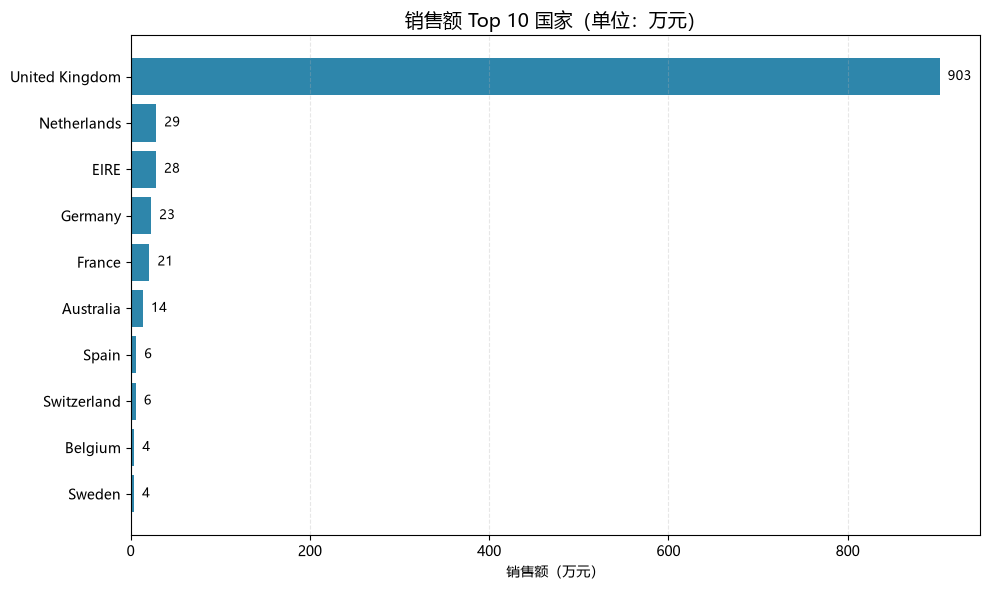

Country
Sweden              3.84
Belgium             4.12
Switzerland         5.71
Spain               6.16
Australia          13.85
France             20.97
Germany            22.89
EIRE               28.35
Netherlands        28.54
United Kingdom    902.52
Name: Sales, dtype: float64


In [8]:
# 销售额 Top 10 的国家
country_sales=(
    clean.groupby("Country")["Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

country_sales_wan = country_sales / 10000

# ---- 画横向条形图 ----
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(country_sales_wan.index, country_sales_wan.values,
               color="#2E86AB")

for bar, v in zip(bars, country_sales_wan.values):
    ax.text(v + max(country_sales_wan.values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{v:,.0f}", va="center", fontsize=9)

ax.set_title("销售额 Top 10 国家（单位：万元）", fontsize=14)
ax.set_xlabel("销售额（万元）")
ax.grid(axis="x", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

print(country_sales_wan.round(2))

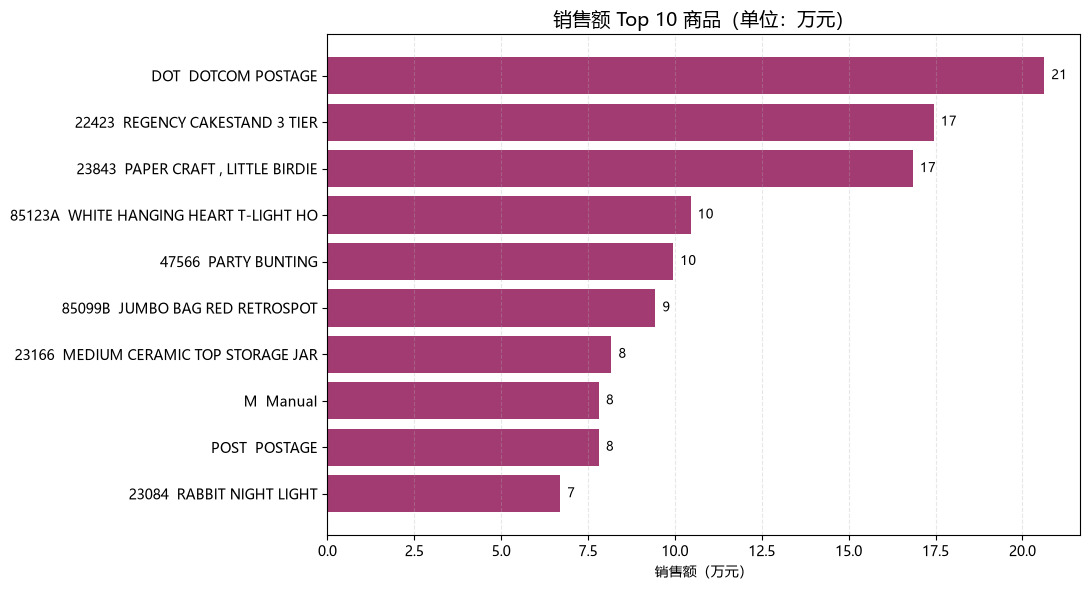

StockCode
23084      6.70
POST       7.81
M          7.81
23166      8.17
85099B     9.43
47566      9.95
85123A    10.45
23843     16.85
22423     17.45
DOT       20.62
Name: Sales, dtype: float64


In [9]:
#销售额 Top 10 的商品
# ---- 按商品聚合：以 StockCode 为主键，取对应 Description ----
product_sales = (
    clean.groupby("StockCode")
    .agg(Description=("Description", "first"),     # 取该编码下第一个非空描述
         Sales=("Sales", "sum"))
    .nlargest(10, "Sales")
    .sort_values("Sales")
)

product_sales_wan = product_sales["Sales"] / 10000

# ---- y 轴标签：截断长名字，避免重叠 ----
labels = [
    f"{code}  {str(name)[:30]}"
    for code, name in zip(product_sales.index, product_sales["Description"])
]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(labels, product_sales_wan.values, color="#A23B72")

for bar, v in zip(bars, product_sales_wan.values):
    ax.text(v + max(product_sales_wan.values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{v:,.0f}", va="center", fontsize=9)

ax.set_title("销售额 Top 10 商品（单位：万元）", fontsize=14)
ax.set_xlabel("销售额（万元）")
ax.grid(axis="x", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

print(product_sales_wan.round(2))


In [10]:
# 有多少客户只买过一次
#  只统计有 CustomerID 的客户（游客单无法归属）
cust = clean.dropna(subset=["CustomerID"])

#  每个客户的下单次数 = 去重后的发票数 
freq = cust.groupby("CustomerID")["InvoiceNo"].nunique()

one_time = (freq == 1).sum()
total    = len(freq)

print(f"总客户数（有ID）：{total}")
print(f"只买过一次的客户数：{one_time}")
print(f"占比：{one_time / total:.2%}")

# 整体下单次数分布 
print(freq.value_counts().sort_index().head(10))


总客户数（有ID）：4338
只买过一次的客户数：1493
占比：34.42%
InvoiceNo
1     1493
2      835
3      508
4      388
5      242
6      172
7      143
8       98
9       68
10      54
Name: count, dtype: int64


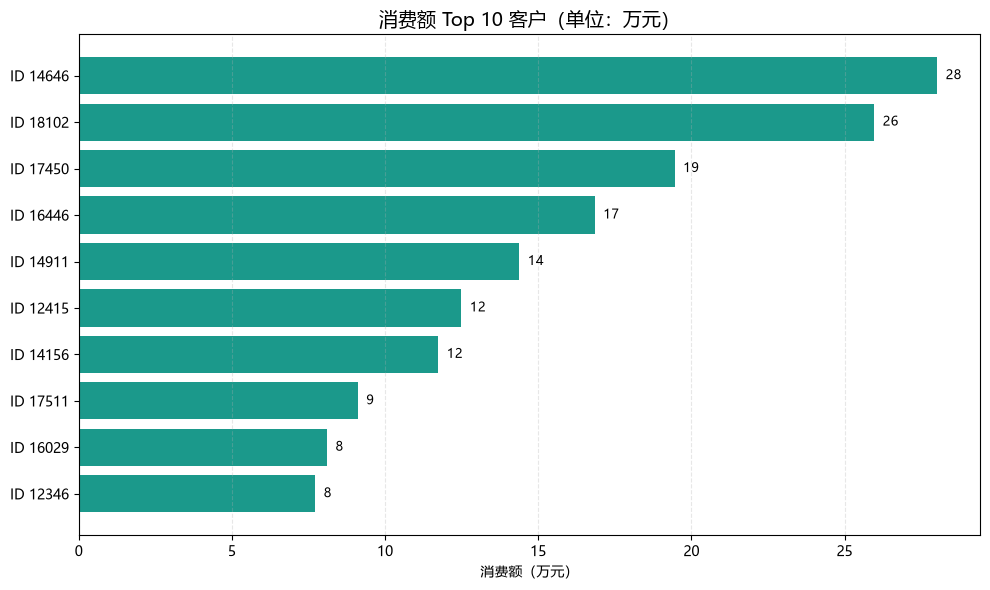

CustomerID
12346.0     7.72
16029.0     8.10
17511.0     9.11
14156.0    11.74
12415.0    12.49
14911.0    14.38
16446.0    16.85
17450.0    19.46
18102.0    25.97
14646.0    28.02
Name: Sales, dtype: float64


In [11]:
#消费 Top 10 客户
# ---- 按客户聚合销售额 ----
cust_sales = (
    clean.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

cust_sales_wan = cust_sales / 10000

# CustomerID 在含缺失列里是 float，转成整数再显示
labels = [f"ID {int(cid)}" for cid in cust_sales.index]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, cust_sales_wan.values, color="#1B998B")

for bar, v in zip(bars, cust_sales_wan.values):
    ax.text(v + max(cust_sales_wan.values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{v:,.0f}", va="center", fontsize=9)

ax.set_title("消费额 Top 10 客户（单位：万元）", fontsize=14)
ax.set_xlabel("消费额（万元）")
ax.grid(axis="x", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

print(cust_sales_wan.round(2))


          客户数    平均R  平均F     平均M
Segment                          
重要价值客户   1311   16.9  9.4  4948.2
一般挽留客户   1252  193.3  1.2   286.1
一般发展客户    515   25.1  1.4   313.4
重要保持客户    456  105.1  4.7  2142.1
重要挽留客户    269  146.7  1.6  1560.7
一般保持客户    203  146.5  3.0   424.0
一般价值客户    199   21.2  3.1   464.0
重要发展客户    133   22.6  1.8  2479.0

总客户数：4338


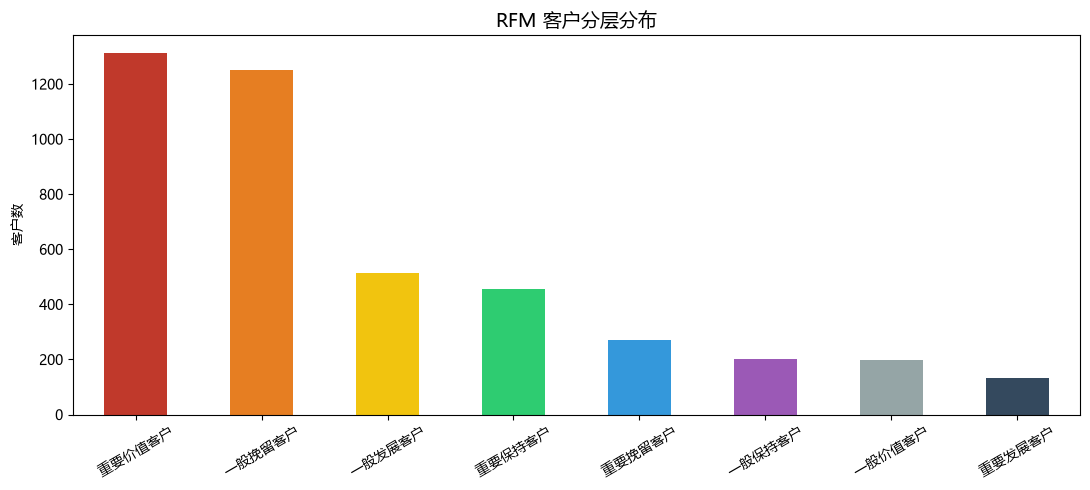

In [12]:
#**RFM 分层**：按 最近购买(R)、购买频率(F)、消费金额(M) 把客户分组
# 客户数据 
cust = clean.dropna(subset=["CustomerID"]).copy()

#  设定基准日：取数据集中最大日期 + 1 天 
# 因为这是历史数据，基准日 = 数据末日
snapshot_date = cust["InvoiceDate"].max() + pd.Timedelta(days=1)

#  按客户聚合 R / F / M 
rfm = cust.groupby("CustomerID").agg(
    R=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),  # 最近一次购买距今天数
    F=("InvoiceNo", "nunique"),                                    # 购买次数（去重发票）
    M=("Sales", "sum")                                             # 总消费额
).reset_index()

#  打 4 分位（qcut） 
# R 越小越好 → 用负号让"小=高分"
# F、M 越大越好
rfm["R_score"] = pd.qcut(-rfm["R"], 4, labels=[1, 2, 3, 4]).astype(int)
rfm["F_score"] = pd.qcut(rfm["F"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_score"] = pd.qcut(rfm["M"], 4, labels=[1, 2, 3, 4]).astype(int)

#  以均值为界，判高/低，分 8 类 
r_med = rfm["R_score"].mean()
f_med = rfm["F_score"].mean()
m_med = rfm["M_score"].mean()

def label_customer(row):
    r_high = row["R_score"] >= r_med
    f_high = row["F_score"] >= f_med
    m_high = row["M_score"] >= m_med
    if r_high and f_high and m_high:  return "重要价值客户"
    if not r_high and f_high and m_high: return "重要保持客户"
    if r_high and not f_high and m_high: return "重要发展客户"
    if not r_high and not f_high and m_high: return "重要挽留客户"
    if r_high and f_high and not m_high:  return "一般价值客户"
    if not r_high and f_high and not m_high: return "一般保持客户"
    if r_high and not f_high and not m_high: return "一般发展客户"
    return "一般挽留客户"

rfm["Segment"] = rfm.apply(label_customer, axis=1)

# 结果 
seg_summary = rfm.groupby("Segment").agg(
    客户数=("CustomerID", "count"),
    平均R=("R", "mean"),
    平均F=("F", "mean"),
    平均M=("M", "mean"),
).sort_values("客户数", ascending=False).round(1)

print(seg_summary)
print(f"\n总客户数：{len(rfm)}")

# 画图：各层客户数 
fig, ax = plt.subplots(figsize=(11, 5))
counts = rfm["Segment"].value_counts()
colors = ["#C0392B", "#E67E22", "#F1C40F", "#2ECC71",
          "#3498DB", "#9B59B6", "#95A5A6", "#34495E"]
counts.plot(kind="bar", ax=ax, color=colors)
ax.set_title("RFM 客户分层分布", fontsize=14)
ax.set_ylabel("客户数")
ax.set_xlabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


总发票数：25,900
取消发票数：3,836
发票维度取消率：14.81%
行维度取消率：1.71%


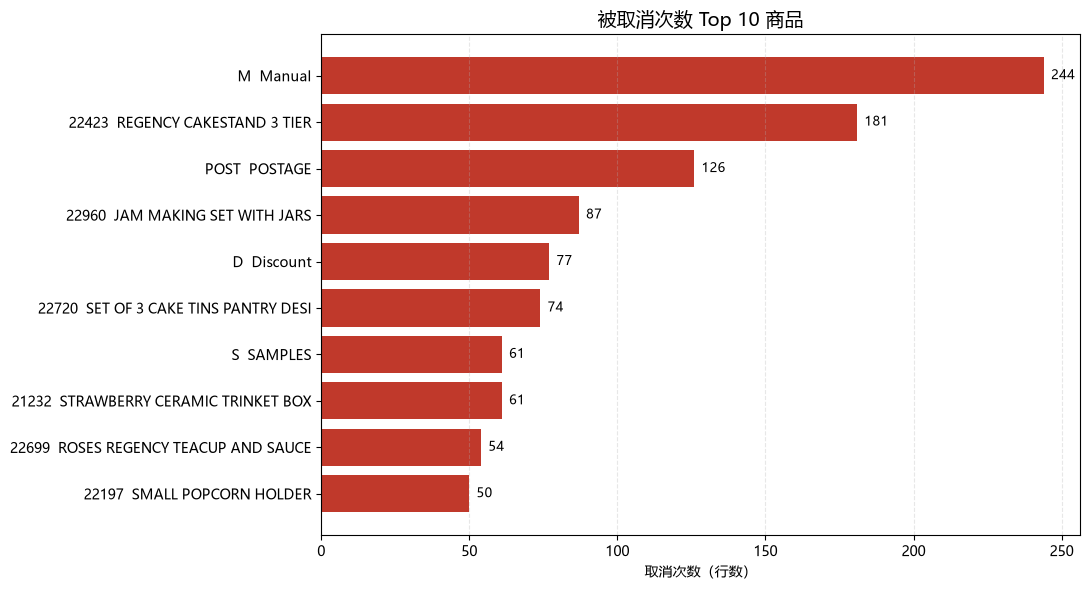

                                 Description  取消次数  取消件数
StockCode                                               
22197                   SMALL POPCORN HOLDER    50   471
22699       ROSES REGENCY TEACUP AND SAUCER     54   437
21232         STRAWBERRY CERAMIC TRINKET BOX    61   385
S                                    SAMPLES    61    61
22720      SET OF 3 CAKE TINS PANTRY DESIGN     74   157
D                                   Discount    77  1194
22960               JAM MAKING SET WITH JARS    87   247
POST                                 POSTAGE   126   147
22423               REGENCY CAKESTAND 3 TIER   181   857
M                                     Manual   244  4066


In [13]:
# 取消订单：取消率是多少？哪些商品被取消最多？
# 重要：这里必须用 raw(含取消单),不能用 df / clean(已删除取消单)
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# ---- 取消率 ----
total_invoices = raw["InvoiceNo"].nunique()
cancel_invoices = raw.loc[raw["InvoiceNo"].str.startswith("C"), "InvoiceNo"].nunique()

print(f"总发票数：{total_invoices:,}")
print(f"取消发票数：{cancel_invoices:,}")
print(f"发票维度取消率：{cancel_invoices / total_invoices:.2%}")

# 行维度取消率
total_rows = len(raw)
cancel_rows = raw["InvoiceNo"].str.startswith("C").sum()
print(f"行维度取消率：{cancel_rows / total_rows:.2%}")

# ---- 被取消最多的商品 Top 10 ----
df_cancel = raw[raw["InvoiceNo"].str.startswith("C")].copy()

cancel_by_product = (
    df_cancel.groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        取消次数=("InvoiceNo", "count"),
        取消件数=("Quantity", lambda x: -x.sum()),
    )
    .nlargest(10, "取消次数")
    .sort_values("取消次数")
)

labels = [f"{c}  {str(n)[:30]}" for c, n in
          zip(cancel_by_product.index, cancel_by_product["Description"])]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(labels, cancel_by_product["取消次数"], color="#C0392B")

for bar, v in zip(bars, cancel_by_product["取消次数"]):
    ax.text(v + cancel_by_product["取消次数"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{v}", va="center", fontsize=9)

ax.set_title("被取消次数 Top 10 商品", fontsize=14)
ax.set_xlabel("取消次数（行数）")
ax.grid(axis="x", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

print(cancel_by_product)

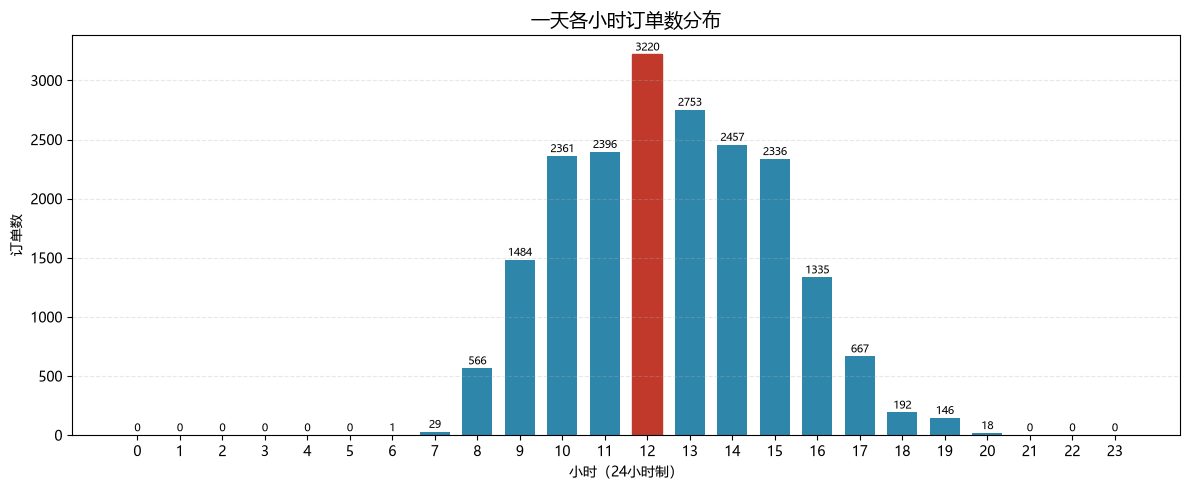

Hour
0        0
1        0
2        0
3        0
4        0
5        0
6        1
7       29
8      566
9     1484
10    2361
11    2396
12    3220
13    2753
14    2457
15    2336
16    1335
17     667
18     192
19     146
20      18
21       0
22       0
23       0
Name: InvoiceNo, dtype: int64

订单高峰时段：12:00 左右


In [14]:
# 时段分析：一天中哪个时段订单最多？（用 InvoiceDate 的小时）
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# ---- 提取小时 ----
clean["Hour"] = clean["InvoiceDate"].dt.hour

# ---- 按小时统计订单数（去重发票数）----
hourly = clean.groupby("Hour")["InvoiceNo"].nunique().reindex(range(24), fill_value=0)

# ---- 画图 ----
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(hourly.index, hourly.values, color="#2E86AB", width=0.7)

# 高亮最高的那个小时
peak_hour = hourly.idxmax()
bars[peak_hour].set_color("#C0392B")

for h, v in zip(hourly.index, hourly.values):
    ax.text(h, v + max(hourly.values) * 0.01, f"{v}",
            ha="center", fontsize=8)

ax.set_title("一天各小时订单数分布", fontsize=14)
ax.set_xlabel("小时（24小时制）")
ax.set_ylabel("订单数")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

print(hourly)
print(f"\n订单高峰时段：{peak_hour}:00 左右")


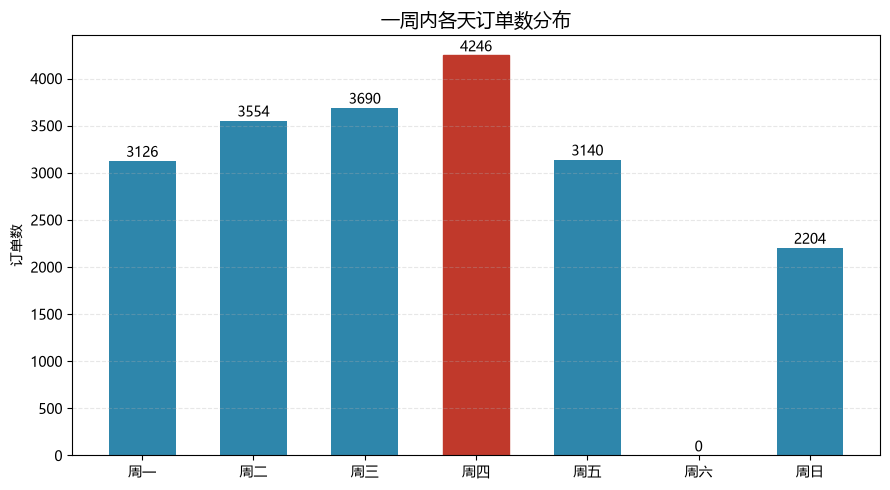

Weekday
0    3126
1    3554
2    3690
3    4246
4    3140
5       0
6    2204
Name: InvoiceNo, dtype: int64

订单最集中：周四


In [15]:
#星期几效应：一周内哪天订单最集中
# ---- 提取星期几（0=周一，6=周日）----
clean["Weekday"] = clean["InvoiceDate"].dt.dayofweek

# ---- 按星期统计订单数 ----
weekday_order = [0, 1, 2, 3, 4, 5, 6]
weekday_labels = ["周一", "周二", "周三", "周四", "周五", "周六", "周日"]

weekly = clean.groupby("Weekday")["InvoiceNo"].nunique().reindex(weekday_order, fill_value=0)

# ---- 画图 ----
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(weekday_labels, weekly.values, color="#2E86AB", width=0.6)

peak = weekly.idxmax()
bars[peak].set_color("#C0392B")

for i, v in enumerate(weekly.values):
    ax.text(i, v + max(weekly.values) * 0.01, f"{v}",
            ha="center", fontsize=10)

ax.set_title("一周内各天订单数分布", fontsize=14)
ax.set_ylabel("订单数")
ax.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

print(weekly)
print(f"\n订单最集中：{weekday_labels[peak]}")


In [16]:
# 找出"只买过一次且金额很低"的客户，占多少？
# ---- 按客户聚合：下单次数 F 和总金额 M ----
cust = clean.dropna(subset=["CustomerID"])

cust_summary = cust.groupby("CustomerID").agg(
    F=("InvoiceNo", "nunique"),
    M=("Sales", "sum")
)

# ---- 定义"金额很低"：用下四分位数（M 的 25% 分位）作为阈值 ----
low_threshold = cust_summary["M"].quantile(0.25)

# ---- 筛选：只买过一次 且 金额低于阈值 ----
mask = (cust_summary["F"] == 1) & (cust_summary["M"] < low_threshold)
target = cust_summary[mask]

total_clients = len(cust_summary)
one_time_clients = (cust_summary["F"] == 1).sum()

print(f"总客户数：{total_clients}")
print(f"只买过一次的客户：{one_time_clients}（{one_time_clients/total_clients:.1%}）")
print(f"金额很低阈值（M 下四分位）：{low_threshold:.2f}")
print(f"只买过一次且金额很低的客户：{len(target)}（{len(target)/total_clients:.1%}）")
print(f"在单次购买客户中，占比：{len(target)/one_time_clients:.1%}")


总客户数：4338
只买过一次的客户：1493（34.4%）
金额很低阈值（M 下四分位）：307.41
只买过一次且金额很低的客户：860（19.8%）
在单次购买客户中，占比：57.6%
